In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import casadi as ca
from IPython.display import clear_output, display
import matplotlib.ticker as ticker
import cvxpy as cp
from sklearn.linear_model import Ridge
import scipy.linalg


def gaussian_kernel(X, Y, sigma=100):
    XX = np.sum(X ** 2, axis=0).reshape(-1, 1)
    YY = np.sum(Y ** 2, axis=0).reshape(1, -1)
    distances = XX + YY - 2 * np.dot(X.T, Y)
    return np.exp(-distances / (2 * sigma ** 2))

def gaussian_kernel_casadi(X1, X2, sigma=1.0):
    """
    Gaussian (RBF) kernel for CasADi symbolic variables.
    
    Args:
        X1: A CasADi MX matrix of shape (n_features, n_samples1)
        X2: A CasADi MX matrix of shape (n_features, n_samples2)
        sigma: The bandwidth parameter of the RBF kernel.
        
    Returns:
        A CasADi MX matrix of shape (n_samples1, n_samples2) representing the kernel matrix.
    """
    # Compute the squared L2 norm of the difference between each pair of points
    X1_sq = ca.sum1(X1**2).T  # Shape (n_samples1, 1)
    X2_sq = ca.sum1(X2**2).T  # Shape (n_samples2, 1)
    
    # Compute the squared Euclidean distance matrix
    sq_dists = X1_sq - 2 * (X1.T @ X2) + X2_sq.T
    
    # Compute the Gaussian kernel matrix
    K = ca.exp(-0.5 / sigma**2 * sq_dists)
    
    return K

def chiuso_kernel(X, Y, sigma, lambda_, T_ini):
    
    # Initialize the kernel matrix
    K = np.zeros((X.shape[1], Y.shape[1]))
    
    # Vectorized computation over the T_ini blocks
    for i in range(T_ini - 1, -1, -1):
        exp_factor = np.exp(-(T_ini - i -1) * lambda_)
        X_sub = X[i*5:(i+1)*5, :]
        Y_sub = Y[i*5:(i+1)*5, :]

        K += exp_factor * gaussian_kernel(X_sub, Y_sub, sigma)
    
    return K

def chiuso_kernel_casadi(X, Y, sigma, lambda_, T_ini):
    # Initialize the kernel matrix
    K = ca.MX.zeros(X.shape[1], Y.size2())
    
    # Vectorized computation over the T_ini blocks
    for i in range(T_ini - 1, -1, -1):
        exp_factor = ca.exp(-(T_ini - i -1) * lambda_)
        X_sub = X[i*5:(i+1)*5, :]
        Y_sub = Y[i*5:(i+1)*5, :]
        
        K += exp_factor * gaussian_kernel_casadi(X_sub, Y_sub, sigma)
    
    return K

In [8]:
# run the simulation either with open or closed loop control, to gather data

np.random.seed(4)

# whether to gather data via open or closed loop
closed_loop = 0
noiseless = 0

# whether to show the animation, faster without
show_animation = 0

# whether to show the predictions, cleaner plot without
show_predictions = 1

# PID controller parameters
Kp_p = -3.2
Ki_p = -0.04
Kd_p = 0.5

Kp_c = -0.2
Ki_c = -0.0005
Kd_c = 0.01

integral_p = 0.0
integral_c = 0.0

if closed_loop:
    numSteps = 800
else:
    numSteps = 500

u = np.random.normal(0, 1, numSteps)
u[int(numSteps/3):int(numSteps/3*2)] *= 3
u[int(numSteps*2 /3):] /= 100
y = np.zeros(numSteps)
x = np.zeros((4, numSteps))


reset_time = []
seed = 3

if show_animation:
    env = gym.make("InvertedPendulum-v4", render_mode="human")
else:
    env = gym.make("InvertedPendulum-v4", render_mode="rgb_array")

# if closed_loop:
#     env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix='cl stabilisation data', step_trigger=lambda x: True)
# else:
#     env = gym.wrappers.RecordVideo(env=env, video_folder='video/ol stabilisation', name_prefix='ol stabilisation data', step_trigger=lambda x: True)
    
obs, info = env.reset(seed=seed)

for k in range(numSteps):
    # Simple PID controller for angle stabilization
    if not noiseless:
        obs += np.random.normal(0, 0.001, (np.size(obs)))
    angle = obs[1]  # Angle of the pendulum
    dangle = obs[3]
    pos = obs[0]
    speed = obs[2]
    error_p = -angle  # Target is 0 angle
    integral_p += error_p
    error_c = -pos  # Target is 0 angle
    integral_c += error_c
    
    if closed_loop:
        u[k] = Kp_p * error_p + Ki_p * integral_p + Kd_p * dangle \
             + Kp_c * error_c + Ki_c * integral_c + Kd_c * speed + np.random.normal(0, 0.1)
        
    x[:,k] = obs
    
    # Clip the control input to the action space limits
    u[k] = np.clip(u[k], env.action_space.low[0], env.action_space.high[0])
    obs, reward, done, truncated, info = env.step([u[k]])
 

    if done or truncated or (np.abs(angle) > 0.2 and not closed_loop) or (np.abs(angle) > 0.3 and closed_loop) or np.abs(pos) > 0.2:	
        seed += 1
        obs, info = env.reset(seed = seed)
        integral_p = 0.0
        integral_c = 0.0
        reset_time += [k]
        
env.close()
reset_time += [k]
y = x

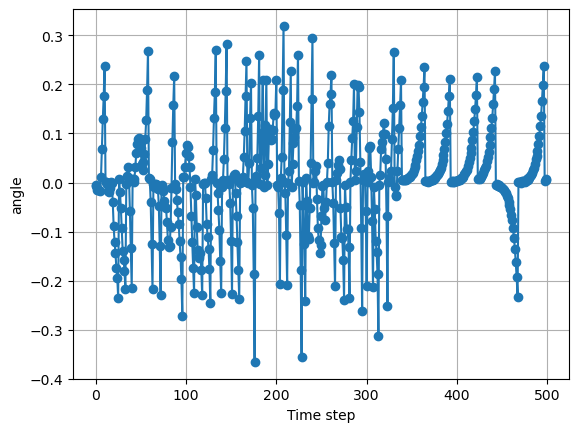

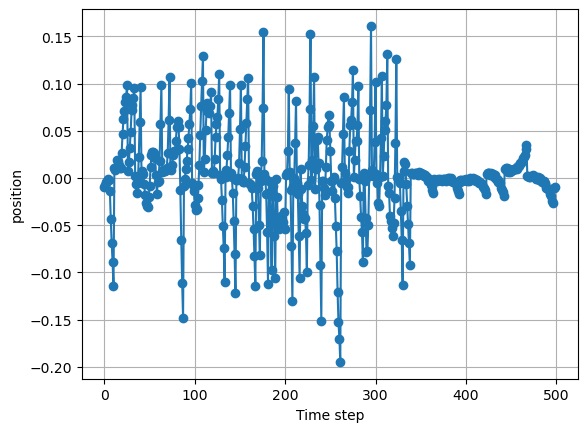

In [4]:
# plot the gathered data

plt.figure()
plt.plot(range(numSteps), x[1,:], '-o')
plt.xlabel('Time step')
plt.ylabel('angle')
plt.grid(True)
plt.show()

plt.figure()
plt.plot(range(numSteps), x[0,:], '-o')
plt.xlabel('Time step')
plt.ylabel('position')
plt.grid(True)
plt.show()

In [97]:
# form the matrices for the Kernel DeePC

T_ini = 1
T_sim = 151

N_o = 20

L_o = T_ini + N_o  # Hankel matrix row
u_ini = np.zeros((T_ini,))
y_ini = np.zeros((T_ini*4,))
gamma = 1e-8
sigma_o = 6
sigma_o_koopman = 5

U_p_o = []
U_f_o = []
Y_p_o = []
Y_f_o = []

last_t = -1
for t in reset_time:
    y_section = y[:, last_t+1:t+1]
    u_section = u[last_t+1:t+1]
    last_t = t
    
    numSteps_section = len(u_section)
    if numSteps_section - L_o > 0:
        H_u_o = np.zeros((L_o, numSteps_section - L_o + 1))
        H_y_o = np.zeros((L_o * 4, numSteps_section - L_o + 1))
        for i in range(L_o):
            H_u_o[i, :] = u_section[i:i + numSteps_section - L_o + 1]
            H_y_o[i*4:(i+1)*4, :] = y_section[:, i:i + numSteps_section - L_o + 1]
        
        U_p_o += [H_u_o[:T_ini, :]]
        U_f_o += [H_u_o[T_ini:, :]]
        
        Y_p_o += [H_y_o[:T_ini*4, :]]
        Y_f_o += [H_y_o[T_ini*4:, :]]
    
U_p_o = np.hstack(U_p_o)
U_f_o = np.hstack(U_f_o)
Y_p_o = np.hstack(Y_p_o)
Y_f_o = np.hstack(Y_f_o)
    
H_o = np.vstack((U_p_o, Y_p_o, U_f_o, Y_f_o))
D_o = np.vstack((U_p_o, Y_p_o, U_f_o))
    
    # Gram matrix
K_o = gaussian_kernel(D_o, D_o, sigma_o)

H_c_o = len(H_o[0])

M_o = Y_f_o @ np.linalg.inv(K_o + gamma * np.eye(H_c_o))

D_o_koopman = np.vstack((U_p_o, Y_p_o))
    
K_koopman_deepc = gaussian_kernel(D_o_koopman[:, :-N_o], D_o_koopman, sigma_o_koopman)

M_Koopman_DeePC = Y_f_o @ np.linalg.pinv(np.vstack((K_koopman_deepc, U_f_o)))

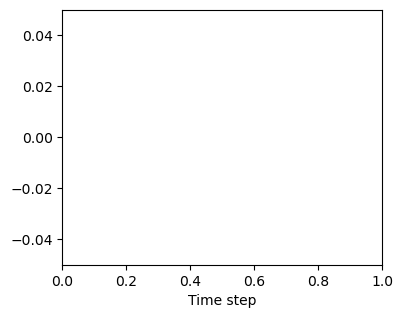

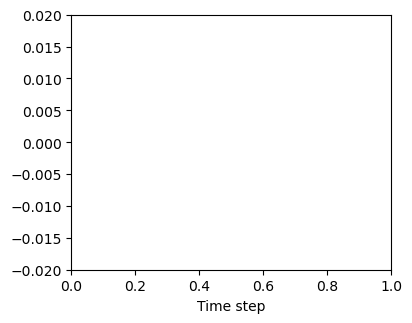

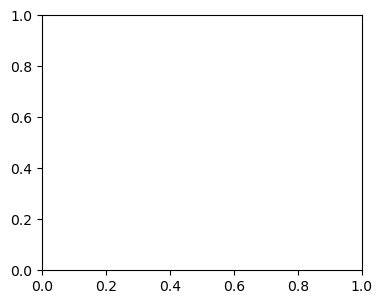

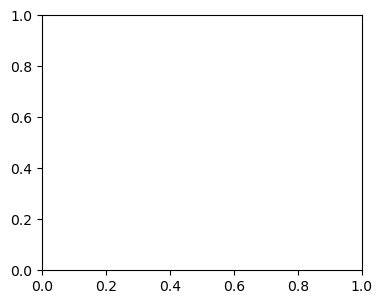

In [13]:
plt.ion()  # Turn on interactive mode

# Create four figures
fig1, ax1 = plt.subplots(figsize=(4, 3))
plt.xlabel('Time step')
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.ylim(-0.05 , 0.05)
fig2, ax2 = plt.subplots(figsize=(4, 3))
plt.xlabel('Time step')
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
plt.ylim(-0.02 , 0.02)
fig3, ax3 = plt.subplots(figsize=(4, 3))
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 
fig4, ax4 = plt.subplots(figsize=(4, 3))
plt.subplots_adjust(left=0.2, bottom=0.15, right=1, top=1) 

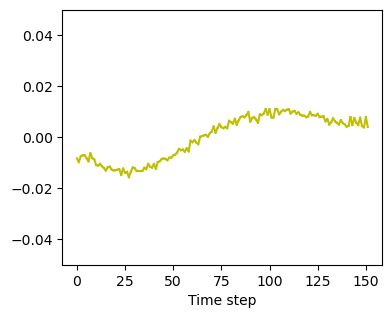

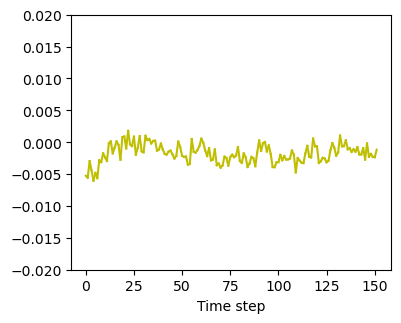

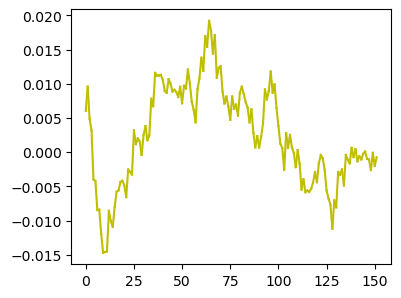

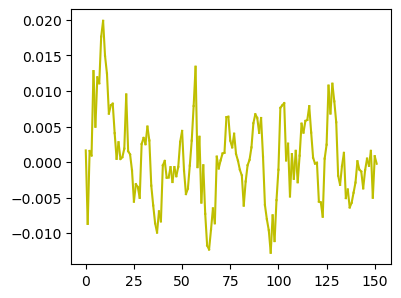

Moviepy - Building video d:\Useless\ETH\Semester Project\code\python\video\RoKDeePC_stabilise_closedloop-step-0.mp4.
Moviepy - Writing video d:\Useless\ETH\Semester Project\code\python\video\RoKDeePC_stabilise_closedloop-step-0.mp4



Moviepy - Done !
Moviepy - video ready d:\Useless\ETH\Semester Project\code\python\video\RoKDeePC_stabilise_closedloop-step-0.mp4


In [102]:
# The Kernel DeePC

u_o = np.zeros((T_sim,))


env = gym.make("InvertedPendulum", render_mode="rgb_array")
if closed_loop:
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'RoKDeePC_stabilise_closedloop', step_trigger=lambda x: True)
else:
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'RoKDeePC_stabilise_openloop', step_trigger=lambda x: True)
    

obs, info = env.reset(seed=3)
lb = env.action_space.low[0]
ub = env.action_space.high[0]

y1 = obs
y_ini = obs

Q =  np.kron(np.eye(N_o),np.diag([1, 1, 0.1, 0.1]))

colors = ['b', 'c', 'm', 'y', 'k']

for i in range(T_sim):
    
    opti = ca.Opti()
    x_o = opti.variable(N_o + 5 * T_ini)
    y_f = opti.variable(4 * N_o)
    #g_o = opti.variable(H_c_o)
    objective = 0
    #objective = ca.sum1(x_o[5*T_ini:] ** 2)
    objective += ca.mtimes([x_o[5 * T_ini:].T, x_o[5 * T_ini:]])
    #objective += ca.mtimes([(Y_f_o @ g_o).T, np.kron(np.eye(N_o),np.diag([10, 1, 0.1, 0.1])), (Y_f_o @ g_o)])
    constraints = []
    gaussian_kernel_ = gaussian_kernel_casadi(D_o, x_o, sigma_o)
    objective += ca.mtimes([y_f.T, Q, y_f])
    #constraints.append((K_o + gamma * ca.MX.eye(H_c_o)) @ g_o == gaussian_kernel_)
    constraints.append(y_f == M_o @ gaussian_kernel_)
    constraints.append(x_o[5*T_ini:] >= lb)
    constraints.append(x_o[5*T_ini:] <= ub)
    constraints.append(x_o[:T_ini] == u_ini)
    constraints.append(x_o[T_ini:5*T_ini] == y_ini)
    
    for constraint in constraints:
        opti.subject_to(constraint)

    # Set the objective in Opti
    opti.minimize(objective)
    
    # Set initial guesses for the variables
    initial_guess = np.zeros(5 * N_o + 5 * T_ini)
    opti.set_initial(ca.vertcat(x_o, y_f), initial_guess)
    
    # Solver options
    opts = {'ipopt.print_level': 0, 'print_time': 0}
    opti.solver('ipopt', opts)
    
    # Solve the problem
    sol = opti.solve()
    
    # Extract the solution
    u_o_opt = sol.value(x_o[5 * T_ini:N_o + 5 * T_ini])
    #g_o_opt = sol.value(g_o)
    y_pred = sol.value(y_f).reshape((4,-1),order='F')
    
    obs, reward, done, truncated, info = env.step([u_ini[-1]])
    obs += np.random.normal(0, 0.001, (np.size(obs)))
    
    u1_o = u_o_opt[0]
    u_o[i] = u1_o
    
    
    u_ini = np.hstack((u_ini, u1_o))[1:]
    y_ini = np.hstack((y_ini, y1))[4:]
    
    y1_old = y1
    y1 = obs

    ax1.plot([i, i+1], [y1_old[0], y1[0]], 'y-', linewidth=1.5)    
    ax2.plot([i, i+1], [y1_old[1], y1[1]], 'y-', linewidth=1.5)    
    ax3.plot([i, i+1], [y1_old[2], y1[2]], 'y-', linewidth=1.5)    
    ax4.plot([i, i+1], [y1_old[3], y1[3]], 'y-', linewidth=1.5)

    if show_predictions:
        #y_pred = (Y_f_o @ g_o_opt).reshape((4,-1),order='F')
        color = colors[i % len(colors)]
        ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '-', linewidth=0.5)
        ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '-', linewidth=0.5)
        ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '-', linewidth=0.5)
        ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '-', linewidth=0.5)
    
    # Redraw the updated plots
    fig1.canvas.draw()
    fig1.canvas.flush_events()
    fig2.canvas.draw()
    fig2.canvas.flush_events()
    fig3.canvas.draw()
    fig3.canvas.flush_events()
    fig4.canvas.draw()
    fig4.canvas.flush_events()
    clear_output(wait=True)
    display(fig1)
    display(fig2)
    display(fig3)
    display(fig4)
    plt.pause(0.001)
    
env.close()

plt.ioff()
plt.show()



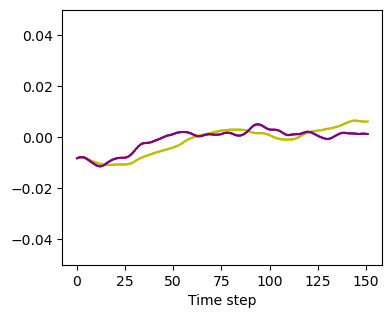

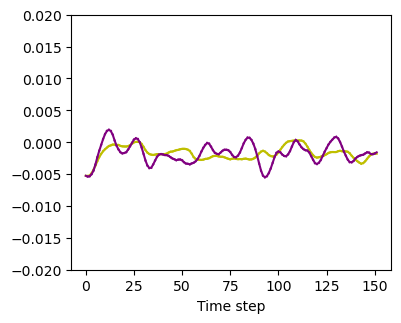

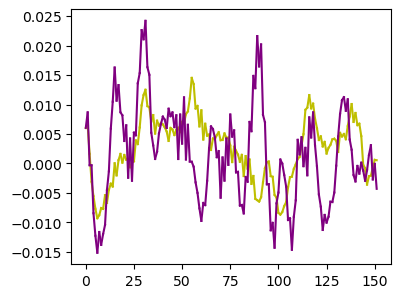

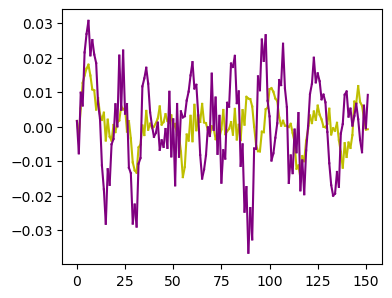

In [100]:
# Koopman DeePC
u_o = np.zeros((T_sim,))


env = gym.make("InvertedPendulum", render_mode="rgb_array")
    

obs, info = env.reset(seed=3)
lb = env.action_space.low[0]
ub = env.action_space.high[0]

y1 = obs
y_ini = obs

colors = ['b', 'c', 'm', 'y', 'k']

Q = np.kron(np.eye(N_o), np.diag([10, 1, 0.1, 0.1]))

# input costs
R = np.kron(np.eye(N_o), np.diag([1]))    

for i in range(T_sim):
    
    z0 = gaussian_kernel(D_o_koopman[:, :-N_o], np.hstack((u_ini, y_ini)).reshape(5, 1), sigma_o_koopman)
        
    # CVXPY problem formulation
    u_f = cp.Variable(N_o)  # control inputs

    objective = 0
    objective += cp.quad_form(M_Koopman_DeePC @ cp.vstack([z0, cp.reshape(u_f, (-1, 1))]), Q)
    objective += cp.quad_form(u_f, R)
                
    # Constraints
    constraints = []
    constraints.append(u_f >= lb)
    constraints.append(u_f <= ub)

    # Define the problem
    problem = cp.Problem(cp.Minimize(objective), constraints)

    # Solve the problem using a convex solver
    problem.solve(solver="SCS", verbose=True)

    # Extract the solution
    u_o_opt = u_f.value
    y_f = M_Koopman_DeePC @ np.vstack([z0, u_o_opt.reshape(-1, 1)])

    
    obs, reward, done, truncated, info = env.step([u_ini[-1]])
    #obs += np.random.normal(0, 0.001, (np.size(obs)))
    
    u1_o = u_o_opt[0]
    u_o[i] = u1_o
    
    
    u_ini = np.hstack((u_ini, u1_o))[1:]
    y_ini = np.hstack((y_ini, y1 + np.random.normal(0, 0.001, (np.size(obs)))))[4:]
    
    y1_old = y1
    y1 = obs

    ax1.plot([i, i+1], [y1_old[0], y1[0]], 'purple', linewidth=1.5)    
    ax2.plot([i, i+1], [y1_old[1], y1[1]], 'purple', linewidth=1.5)    
    ax3.plot([i, i+1], [y1_old[2], y1[2]], 'purple', linewidth=1.5)    
    ax4.plot([i, i+1], [y1_old[3], y1[3]], 'purple', linewidth=1.5)

    if show_predictions:
        y_pred = y_f.reshape((4,-1),order='F')
        color = colors[i % len(colors)]
        ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '-', linewidth=0.5)
        ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '-', linewidth=0.5)
        ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '-', linewidth=0.5)
        ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '-', linewidth=0.5)
    
    # Redraw the updated plots
    fig1.canvas.draw()
    fig1.canvas.flush_events()
    fig2.canvas.draw()
    fig2.canvas.flush_events()
    fig3.canvas.draw()
    fig3.canvas.flush_events()
    fig4.canvas.draw()
    fig4.canvas.flush_events()
    clear_output(wait=True)
    display(fig1)
    display(fig2)
    display(fig3)
    display(fig4)
    plt.pause(0.001)
    
env.close()

plt.ioff()
plt.show()

In [ ]:
# Create the matrices for the Fixed Length Kernel clDeePC

N_c = 1
T_ini = 1
L_c = T_ini + N_c  # Hankel matrix row
sigma_c = 0.6
sigma_c_koopman = 5
N_o = 20
T_sim = 151
u_ini = np.zeros((T_ini,))
y_ini = np.zeros((T_ini*4,))

U_p_c = []
U_f_c = []
Y_p_c = []
Y_f_c = []

last_t = -1
for t in reset_time:
    y_section = y[:, last_t+1:t+1]
    u_section = u[last_t+1:t+1]
    last_t = t
    
    numSteps_section = len(u_section)
    if numSteps_section - L_c > 0:
        H_u_c = np.zeros((L_c, numSteps_section - L_c + 1))
        H_y_c = np.zeros((L_c * 4, numSteps_section - L_c + 1))
        for i in range(L_c):
            H_u_c[i, :] = u_section[i:i + numSteps_section - L_c + 1]
            H_y_c[i*4:(i+1)*4, :] = y_section[:, i:i + numSteps_section - L_c + 1]
        
        U_p_c += [H_u_c[:T_ini, :]]
        U_f_c += [H_u_c[T_ini:, :]]
        
        Y_p_c += [H_y_c[:T_ini*4, :]]
        Y_f_c += [H_y_c[T_ini*4:, :]]
    
U_p_c = np.hstack(U_p_c)
U_f_c = np.hstack(U_f_c)
Y_p_c = np.hstack(Y_p_c)
Y_f_c = np.hstack(Y_f_c)
    
H_c = np.vstack((U_p_c, Y_p_c, U_f_c, Y_f_c))
D_c = np.vstack((U_p_c, Y_p_c))
    
    # Gram matrix
K_c = gaussian_kernel(D_c, D_c, sigma_c)

H_c_c = len(H_c[0])
gamma_c = 1e-4

M1 = Y_f_c @ np.linalg.inv(K_c + gamma_c * np.eye(H_c_c))
M3 = Y_f_c @ np.linalg.pinv(D_c)

Y_lift = gaussian_kernel(D_c, np.vstack((U_f_c, Y_f_c)), sigma_c)

G = np.vstack((K_c, U_f_c)) @ np.vstack((K_c, U_f_c)).T# + 1e-6 * np.eye(K_c.shape[0] + U_p_c.shape[0])

cond_G = np.linalg.cond(G)


V = Y_lift @ np.vstack((K_c, U_f_c)).T
cond_V = np.linalg.cond(V)

ridge = Ridge(alpha=1e-8)  # Regularization strength (alpha)
ridge.fit(G.T, V.T)  # Fit the model

# Extract the solution
M_ridge = ridge.coef_

A = M_ridge[:, :K_c.shape[0]]
B = M_ridge[:, K_c.shape[0]:]

# U_A, S_A, VT_A = np.linalg.svd(A)
# S_A_filtered = S_A[S_A > 1e-4]
# A_rank = len(S_A_filtered)
# A = U_A[:, :A_rank] @ np.diag(S_A_filtered) @ VT_A[:A_rank, :]

E = Y_lift - A @ K_c - B @ U_f_c

eig_A = np.linalg.eigvals(A)
min_eig_A = np.min(np.abs(eig_A))
max_eig_A = np.max(np.abs(eig_A))

n, m = B.shape

def stable_matrix_power(A, exponent, regularization=1e-10):
    # Apply regularization (small perturbation to avoid large condition numbers)
    A_reg = A + regularization * np.eye(A.shape[0])

    # Schur decomposition: A = Q @ T @ Q^H
    Q, T = scipy.linalg.schur(A_reg)
    
    # Compute T^exponent
    T_powered = np.linalg.matrix_power(T, exponent)
    
    # Reconstruct the matrix A^exponent
    A_powered = Q @ T_powered @ np.linalg.inv(Q)
    
    return A_powered


# Construct the A matrix
A_blk = np.zeros((N_o * 4, n))
for i in range(N_o):
    #A_powered = stable_matrix_power(A, i + 1)
    #A_blk[i * 4:(i + 1) * 4, :] = M1 @ A_powered
    A_blk[i * 4:(i + 1) * 4, :] = M1 @ np.linalg.matrix_power(A, i)

# Construct the B matrix
B_blk = np.zeros((N_o * 4, N_o * m))
for i in range(N_o):
    for j in range(i):  # Only fill lower triangular part
        #A_powered = stable_matrix_power(A, i - j)
        #B_blk[i * 4:(i + 1) * 4, j * m:(j + 1) * m] = M1 @ A_powered @ B
        B_blk[i * 4:(i + 1) * 4, j * m:(j + 1) * m] = M1 @ np.linalg.matrix_power(A, i - j - 1) @ B
        
cond_A_blk = np.linalg.cond(A_blk)
cond_B_blk = np.linalg.cond(B_blk)

U_A, S_A, VT_A = np.linalg.svd(A_blk)
U_B, S_B, VT_B = np.linalg.svd(B_blk)

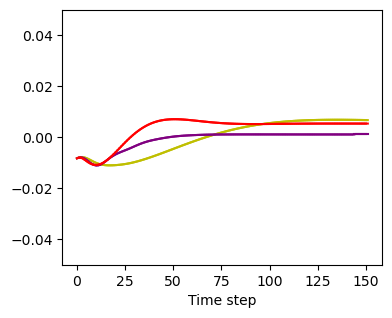

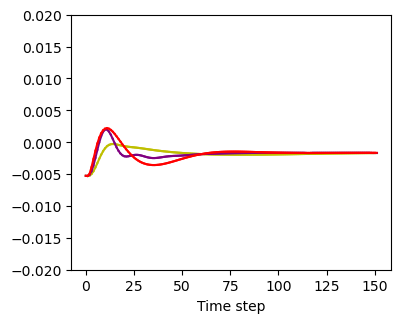

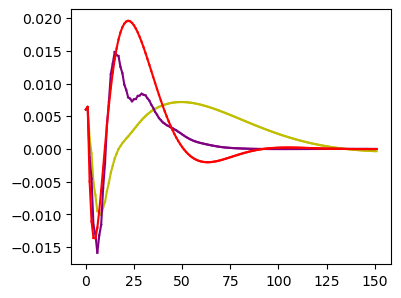

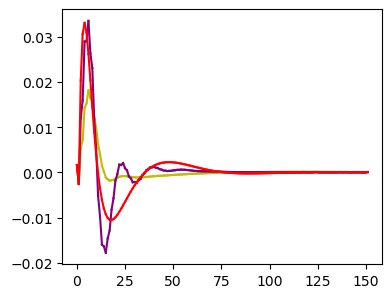

Moviepy - Building video d:\Useless\ETH\Semester Project\code\python\video\Fixed_Length_Kernel_clDeePC_stabilise_closedloop-step-0.mp4.
Moviepy - Writing video d:\Useless\ETH\Semester Project\code\python\video\Fixed_Length_Kernel_clDeePC_stabilise_closedloop-step-0.mp4



Moviepy - Done !
Moviepy - video ready d:\Useless\ETH\Semester Project\code\python\video\Fixed_Length_Kernel_clDeePC_stabilise_closedloop-step-0.mp4


In [ ]:
# The Fixed Length Kernel clDeePC

x0 = np.array([0, 0])
y1 = 0

u_c = np.zeros((T_sim,))

env = gym.make("InvertedPendulum", render_mode="rgb_array")
if closed_loop:
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'Fixed_Length_Kernel_clDeePC_stabilise_closedloop', step_trigger=lambda x: True)
else:
    env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'Fixed_Length_Kernel_clDeePC_stabilise_openloop', step_trigger=lambda x: True)
    

obs, info = env.reset(seed=3)
env.start_video_recorder()

lb = env.action_space.low[0]
ub = env.action_space.high[0]

y1 = obs
y_ini = obs

colors = ['b', 'c', 'm', 'y', 'k']

for i in range(T_sim):
    
    opti = ca.Opti()
    x_c = opti.variable(5 * N_o + 5 * T_ini)
    objective = 0
    D = np.zeros((N_o, N_o))
    D[-1, -1] = 3
    objective += ca.mtimes([x_c[5*T_ini:].T, np.kron(np.eye(N_o),np.diag([1, 10, 1, 0.1, 0.1])), x_c[5*T_ini:]])
    constraints = []
    for k in range(N_o):
        constraints.append(x_c[5*T_ini + 5*k + 1 : 5*T_ini + 5*k + 5] == M1 @ gaussian_kernel_casadi(D_c, x_c[5*T_ini + 5*(k-1) : 5*T_ini + 5*(k-1) + 5], sigma_c))
    constraints.append(x_c[5*T_ini::5] >= lb)
    constraints.append(x_c[5*T_ini::5] <= ub)
    constraints.append(x_c[:T_ini] == u_ini)
    constraints.append(x_c[T_ini:5*T_ini] == y_ini)
    
    for constraint in constraints:
        opti.subject_to(constraint)

    # Set the objective in Opti
    opti.minimize(objective)
    
    # Set initial guesses for the variables
    initial_guess = np.zeros(5 * N_o + 5 * T_ini)
    opti.set_initial(x_c, initial_guess)
    
    # Solver options
    opts = {'ipopt.print_level': 0, 'print_time': 0}
    opti.solver('ipopt', opts)
    
    # Solve the problem
    sol = opti.solve()
    
    # Extract the solution
    u_c_opt = sol.value(x_c[5*T_ini::5])
    chunks = [sol.value(x_c[i:i + 5]) for i in range(5*T_ini, (N_o + T_ini) * 5, 5)]
    y_pred_ = [chunk[-4:] for chunk in chunks]
    y_pred = np.concatenate(y_pred_)
    
    obs, reward, done, truncated, info = env.step([u_ini[-1]])
    #obs += np.random.normal(0, 0.001, (np.size(obs)))
    
    u1_c = u_c_opt[0]
    u_c[i] = u1_c
    y1_old = y1
    y1 = obs
    
    u_ini = np.hstack((u_ini, u1_c))[1:]
    y_ini = np.hstack((y_ini, y1))[4:]
    
    ax1.plot([i, i+1], [y1_old[0], y1[0]], 'r-', linewidth=1.5)    
    ax2.plot([i, i+1], [y1_old[1], y1[1]], 'r-', linewidth=1.5)    
    ax3.plot([i, i+1], [y1_old[2], y1[2]], 'r-', linewidth=1.5)    
    ax4.plot([i, i+1], [y1_old[3], y1[3]], 'r-', linewidth=1.5)
    
    if show_predictions:
        y_pred = y_pred.reshape((4,-1),order='F')
        color = colors[i % len(colors)]
        ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '-', linewidth=0.5)
        ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '-', linewidth=0.5)
        ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '-', linewidth=0.5)
        ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '-', linewidth=0.5)
    
    # Redraw the updated plots
    fig1.canvas.draw()
    fig1.canvas.flush_events()
    fig2.canvas.draw()
    fig2.canvas.flush_events()
    fig3.canvas.draw()
    fig3.canvas.flush_events()
    fig4.canvas.draw()
    fig4.canvas.flush_events()
    clear_output(wait=True)
    display(fig1)
    display(fig2)
    display(fig3)
    display(fig4)
    plt.pause(0.001)
    
env.close_video_recorder()
env.close()

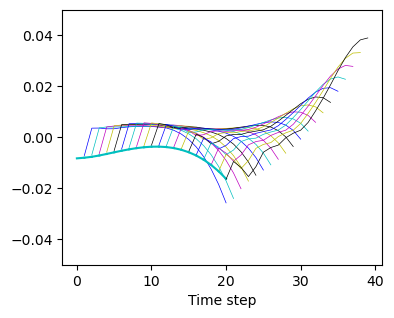

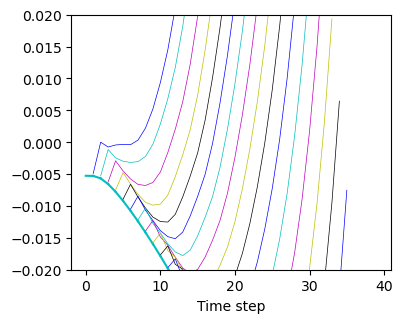

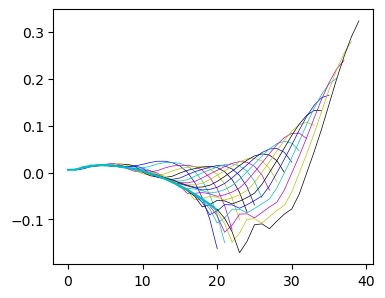

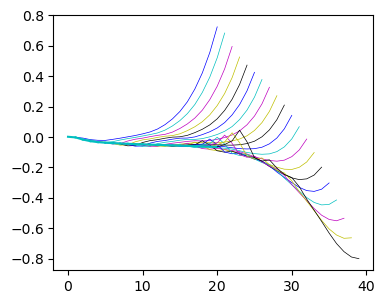

                                     CVXPY                                     
                                     v1.5.2                                    
(CVXPY) Mar 24 02:45:02 PM: Your problem has 20 variables, 40 constraints, and 0 parameters.
(CVXPY) Mar 24 02:45:02 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Mar 24 02:45:02 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Mar 24 02:45:02 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Mar 24 02:45:02 PM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Mar 24 02:45:02 PM: Compiling problem (target solver=SCS).
(CVX

KeyboardInterrupt: 

In [14]:
# Koopman MPC
x0 = np.array([0, 0])
y1 = 0

u_c = np.zeros((T_sim,))

env = gym.make("InvertedPendulum", render_mode="rgb_array")

obs, info = env.reset(seed=3)

lb = env.action_space.low[0]
ub = env.action_space.high[0]

y1 = obs
y_ini = obs

colors = ['b', 'c', 'm', 'y', 'k']

Q = np.kron(np.eye(N_o), np.diag([10, 1, 0.1, 0.1]))

# input costs
R = np.kron(np.eye(N_o), np.diag([1]))

H = R + B_blk.T @ Q @ B_blk
G = 2 * A_blk.T @ Q @ B_blk

eig_H = np.linalg.eigvals(H)

for i in range(T_sim):
    
    z0 = gaussian_kernel(D_c, np.hstack((u_ini, y_ini)).reshape(5, 1), sigma_c)
        
    # CVXPY problem formulation
    u_f = cp.Variable(N_o)  # control inputs

    objective = 0

    objective += cp.quad_form(u_f, cp.psd_wrap(H)) + z0.T @ G @ u_f
            
    # Constraints
    constraints = []
    constraints.append(u_f >= lb)
    constraints.append(u_f <= ub)

    # Define the problem
    problem = cp.Problem(cp.Minimize(objective), constraints)

    # Solve the problem using a convex solver
    problem.solve(solver="SCS", verbose=True)

    # Extract the solution
    u_c_opt = u_f.value
    y_f = A_blk @ z0 + B_blk @ u_c_opt.reshape((N_o, 1))
    y_pred = y_f.reshape((4, -1), order='F')
    
    obs, reward, done, truncated, info = env.step([u_ini[-1]])
    #obs += np.random.normal(0, 0.001, (np.size(obs)))
    
    u1_c = u_c_opt[0]
    u_c[i] = u1_c
    y1_old = y1
    y1 = obs
    
    u_ini = np.hstack((u_ini, u1_c))[1:]
    y_ini = np.hstack((y_ini, y1))[4:]
    
    ax1.plot([i, i+1], [y1_old[0], y1[0]], 'c-', linewidth=1.5)    
    ax2.plot([i, i+1], [y1_old[1], y1[1]], 'c-', linewidth=1.5)    
    ax3.plot([i, i+1], [y1_old[2], y1[2]], 'c-', linewidth=1.5)    
    ax4.plot([i, i+1], [y1_old[3], y1[3]], 'c-', linewidth=1.5)
    
    if show_predictions:
        y_pred = y_pred.reshape((4,-1),order='F')
        color = colors[i % len(colors)]
        ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '-', linewidth=0.5)
        ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '-', linewidth=0.5)
        ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '-', linewidth=0.5)
        ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '-', linewidth=0.5)
    
    # Redraw the updated plots
    fig1.canvas.draw()
    fig1.canvas.flush_events()
    fig2.canvas.draw()
    fig2.canvas.flush_events()
    fig3.canvas.draw()
    fig3.canvas.flush_events()
    fig4.canvas.draw()
    fig4.canvas.flush_events()
    clear_output(wait=True)
    display(fig1)
    display(fig2)
    display(fig3)
    display(fig4)
    plt.pause(0.001)
    
env.close()

In [ ]:
# # The clDeePC

# x0 = np.array([0, 0])
# y1 = 0

# u_c = np.zeros((T_sim,))

# env = gym.make("InvertedPendulum", render_mode="rgb_array")
# if closed_loop:
#     env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'clDeePC_stabilise_closedloop', step_trigger=lambda x: True)
# else:
#     env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'clDeePC_stabilise_openloop', step_trigger=lambda x: True)
    

# obs, info = env.reset(seed=3)
# env.start_video_recorder()

# lb = env.action_space.low[0]
# ub = env.action_space.high[0]

# y1 = obs
# y_ini = obs

# colors = ['b', 'c', 'm', 'y', 'k']

# for i in range(T_sim):
    
#     opti = ca.Opti()
#     x_c = opti.variable(5 * N_o + 5 * T_ini)
#     objective = 0
#     D = np.zeros((N_o, N_o))
#     D[-1, -1] = 3
#     objective += ca.mtimes([x_c[5*T_ini:].T, np.kron(np.eye(N_o),np.diag([1, 10, 1, 0.1, 0.1])), x_c[5*T_ini:]])
#     constraints = []
#     for k in range(N_o):
#         constraints.append(x_c[5*T_ini + 5*k + 1 : 5*T_ini + 5*k + 5] == M3 @ x_c[5*T_ini + 5*(k-1) : 5*T_ini + 5*(k-1) + 5])
#     constraints.append(x_c[5*T_ini::5] >= lb)
#     constraints.append(x_c[5*T_ini::5] <= ub)
#     constraints.append(x_c[:T_ini] == u_ini)
#     constraints.append(x_c[T_ini:5*T_ini] == y_ini)
    
#     for constraint in constraints:
#         opti.subject_to(constraint)

#     # Set the objective in Opti
#     opti.minimize(objective)
    
#     # Set initial guesses for the variables
#     initial_guess = np.zeros(5 * N_o + 5 * T_ini)
#     opti.set_initial(x_c, initial_guess)
    
#     # Solver options
#     opts = {'ipopt.print_level': 0, 'print_time': 0}
#     opti.solver('ipopt', opts)
    
#     # Solve the problem
#     sol = opti.solve()
    
#     # Extract the solution
#     u_c_opt = sol.value(x_c[5*T_ini::5])
#     chunks = [sol.value(x_c[i:i + 5]) for i in range(5*T_ini, (N_o + T_ini) * 5, 5)]
#     y_pred_ = [chunk[-4:] for chunk in chunks]
#     y_pred = np.concatenate(y_pred_)
    
#     obs, reward, done, truncated, info = env.step([u_ini[-1]])
    
#     u1_c = u_c_opt[0]
#     u_c[i] = u1_c
#     y1_old = y1
#     y1 = obs
    
#     u_ini = np.hstack((u_ini, u1_c))[1:]
#     y_ini = np.hstack((y_ini, y1))[4:]
    
#     ax1.plot([i, i+1], [y1_old[0], y1[0]], 'g-', linewidth=1.5)    
#     ax2.plot([i, i+1], [y1_old[1], y1[1]], 'g-', linewidth=1.5)    
#     ax3.plot([i, i+1], [y1_old[2], y1[2]], 'g-', linewidth=1.5)    
#     ax4.plot([i, i+1], [y1_old[3], y1[3]], 'g-', linewidth=1.5)
    
#     if show_predictions:
#         y_pred = y_pred.reshape((4,-1),order='F')
#         color = colors[i % len(colors)]
#         ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '-', linewidth=0.5)
#         ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '-', linewidth=0.5)
#         ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '-', linewidth=0.5)
#         ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '-', linewidth=0.5)
    
#     # Redraw the updated plots
#     fig1.canvas.draw()
#     fig1.canvas.flush_events()
#     fig2.canvas.draw()
#     fig2.canvas.flush_events()
#     fig3.canvas.draw()
#     fig3.canvas.flush_events()
#     fig4.canvas.draw()
#     fig4.canvas.flush_events()
#     clear_output(wait=True)
#     display(fig1)
#     display(fig2)
#     display(fig3)
#     display(fig4)
#     plt.pause(0.001)
    
# env.close_video_recorder()
# env.close()




In [ ]:
# # Create the matrices for the transient Kernel clDeePC

# N_c = 1
# T_ini = 1
# slope = 20
# sigma_c = 3
# gamma_c = 1e-8
# N_o = 20
# T_sim = 151
# lambda_ = 2
# u_ini = np.zeros((T_ini,))
# y_ini = np.zeros((T_ini*4,))

# M1t = dict()
# D_ct = dict()
# sigma_ct = dict()

# for T_ini in range(1,21):
#     U_p_c = []
#     U_f_c = []
#     Y_p_c = []
#     Y_f_c = []
#     last_t = -1
#     L_c = T_ini + N_c
#     sigma_ct[T_ini] = sigma_c
#     for t in reset_time:

#         y_section = y[:, last_t+1:t+1]
#         u_section = u[last_t+1:t+1]
#         last_t = t
        
#         numSteps_section = len(u_section)
        
#         if numSteps_section - L_c > 0:
#             H_u_c = np.zeros((L_c, numSteps_section - L_c + 1))
#             H_y_c = np.zeros((L_c * 4, numSteps_section - L_c + 1))
#             for i in range(L_c):
#                 H_u_c[i, :] = u_section[i:i + numSteps_section - L_c + 1]
#                 H_y_c[i*4:(i+1)*4, :] = y_section[:, i:i + numSteps_section - L_c + 1]
            
#             U_p_c += [H_u_c[:T_ini, :]]
#             U_f_c += [H_u_c[T_ini:, :]]
            
#             Y_p_c += [H_y_c[:T_ini*4, :]]
#             Y_f_c += [H_y_c[T_ini*4:, :]]
    
#     U_p_c = np.hstack(U_p_c)
#     U_f_c = np.hstack(U_f_c)
#     Y_p_c = np.hstack(Y_p_c)
#     Y_f_c = np.hstack(Y_f_c)
        
#     H_c = np.vstack((U_p_c, Y_p_c, U_f_c, Y_f_c))
#     D_ct[T_ini] = []
#     for i in range(T_ini):
#         D_ct[T_ini] += [U_p_c[i, :]]
#         D_ct[T_ini] += [Y_p_c[i*4:(i+1)*4, :]]
        
#     D_ct[T_ini] = np.vstack(D_ct[T_ini])
        
#     # Gram matrix
#     K_c = chiuso_kernel(D_ct[T_ini], D_ct[T_ini], sigma_ct[T_ini], lambda_, T_ini)

#     H_c_c = len(H_c[0])

#     M1t[T_ini] = Y_f_c @ np.linalg.inv(K_c + gamma_c * np.eye(H_c_c))
    

In [ ]:
# # The Transient Kernel clDeePC

# T_ini = 1
# env = gym.make("InvertedPendulum-v4", render_mode="rgb_array")
# if closed_loop:
#     env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'Transient_Kernel_clDeePC_stabilise_closedloop', step_trigger=lambda x: True)
# else:
#     env = gym.wrappers.RecordVideo(env=env, video_folder='video', name_prefix = 'Transient_Kernel_clDeePC_stabilise_openloop', step_trigger=lambda x: True)

# obs, info = env.reset(seed=3)
# env.start_video_recorder()

# lb = env.action_space.low[0]
# ub = env.action_space.high[0]

# y1_c = obs
# y_ini = obs
# y1_old = y1_c
# u_c = np.zeros((T_sim,))

# colors = ['b', 'c', 'm', 'y', 'k']
    
# for i in range(T_sim):

#     opti = ca.Opti()
#     objective = 0
   
#     x_c = opti.variable(5 * N_o + 5 * T_ini)
#     objective += ca.mtimes([x_c[5*T_ini:].T, np.kron(np.eye(N_o),np.diag([1, 10, 1, 0.1, 0.1])), x_c[5*T_ini:]])
    
#     constraints = []
#     for k in range(N_o):
#         constraints.append(x_c[5*T_ini + 5*k + 1 : 5*T_ini + 5*k + 5] == M1t[k+1] @ chiuso_kernel_casadi(D_ct[k+1], x_c[: 5*T_ini + 5*k], sigma_ct[k+1], lambda_, k+1))
#     constraints.append(x_c[5*T_ini::5] >= lb)
#     constraints.append(x_c[5*T_ini::5] <= ub)
#     constraints.append(x_c[:T_ini] == u_ini)
#     constraints.append(x_c[T_ini:5*T_ini] == y_ini)
    
#     for constraint in constraints:
#         opti.subject_to(constraint)

#     # Set the objective in Opti
#     opti.minimize(objective)
    
#     # Set initial guesses for the variables
#     initial_guess = np.zeros(5 * N_o + 5 * T_ini)
#     opti.set_initial(x_c, initial_guess)
    
#     # Solver options
#     opts = {'ipopt.print_level': 0, 'print_time': 0}
#     opti.solver('ipopt', opts)
    
#     # Solve the problem
#     sol = opti.solve()
    
#     # Extract the solution
#     u_c_opt = sol.value(x_c[5*T_ini::5])
#     chunks = [sol.value(x_c[i:i + 5]) for i in range(5*T_ini, (N_o + T_ini) * 5, 5)]
#     y_pred_ = [chunk[-4:] for chunk in chunks]
#     y_pred = np.concatenate(y_pred_)
    
#     obs, reward, done, truncated, info = env.step([u_ini[-1]])
#     obs += np.random.normal(0, 0.00001, (np.size(obs)))
    
#     if N_o == 1:
#         u1_c = u_c_opt
#     else:
#         u1_c = u_c_opt[0]
#     u_c[i] = u_ini[-1]
    
    
#     y1_c = obs
    
#     u_ini = np.hstack((u_ini, u1_c))[1:]
#     y_ini = np.hstack((y_ini, y1_c))[4:]
    
#     if show_predictions:
#         y_pred = y_pred.reshape((4,-1),order='F')
#         color = colors[i % len(colors)]
        
#         ax1.plot(np.arange(i+1, i +1 + N_o), y_pred[0,:], color + '-', linewidth=0.5)
#         ax2.plot(np.arange(i+1, i +1 + N_o), y_pred[1,:], color + '-', linewidth=0.5)
#         ax3.plot(np.arange(i+1, i +1 + N_o), y_pred[2,:], color + '-', linewidth=0.5)
#         ax4.plot(np.arange(i+1, i +1 + N_o), y_pred[3,:], color + '-', linewidth=0.5)
        
#     if i % 5 == 0 and i > 0:
        
#         ax1.plot([i-4, i+1], [y1_old[0], y1_c[0]], 'm--', linewidth=1.5, dashes=[3, 5])        
#         ax2.plot([i-4, i+1], [y1_old[1], y1_c[1]], 'm--', linewidth=1.5, dashes=[3, 5])        
#         ax3.plot([i-4, i+1], [y1_old[2], y1_c[2]], 'm--', linewidth=1.5, dashes=[3, 5])        
#         ax4.plot([i-4, i+1], [y1_old[3], y1_c[3]], 'm--', linewidth=1.5, dashes=[3, 5])
#         y1_old = y1_c

#         # Redraw the updated plots
#         fig1.canvas.draw()
#         fig1.canvas.flush_events()
#         fig2.canvas.draw()
#         fig2.canvas.flush_events()
#         fig3.canvas.draw()
#         fig3.canvas.flush_events()
#         fig4.canvas.draw()
#         fig4.canvas.flush_events()
#         clear_output(wait=True)
#         display(fig1)
#         display(fig2)
#         display(fig3)
#         display(fig4)
#         plt.pause(0.001)

# env.close_video_recorder()
# env.close()

# plt.ioff()
# plt.show()

    


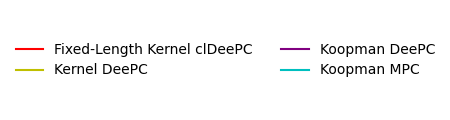

In [ ]:
# if closed_loop:
#     fig2.gca().yaxis.set_major_locator(ticker.MultipleLocator(base=np.pi / 2))
#     fig2.gca().yaxis.set_major_formatter(
#         ticker.FuncFormatter(lambda val, pos: (
#             "0" if val == 0 else
#             "π" if np.isclose(val, np.pi) else
#             "2π" if np.isclose(val, 2 * np.pi) else
#             "π/2" if np.isclose(val, np.pi / 2) else
#             "3π/2" if np.isclose(val, 3 * np.pi / 2) else
#             f"{val / np.pi:.0g}π"
#         ))
#     )
# else:
ax2.set_yticks([tick for tick in ax2.get_yticks() if tick not in [0.02, -0.02]])
ax2.plot([0, 151], [0, 0], color='black', linewidth=1)
ax1.plot([0, 151], [0, 0], color='black', linewidth=1)


if closed_loop:
    if noiseless:
        fig1.savefig('plots/stabilise/cl position noiseless.pdf')
        fig2.savefig('plots/stabilise/cl angle noiseless.pdf')
        fig3.savefig('plots/stabilise/cl linear velocity noiseless.pdf')
        fig4.savefig('plots/stabilise/cl angular velocity noiseless.pdf')
    else:
        fig1.savefig('plots/stabilise/cl position.pdf')
        fig2.savefig('plots/stabilise/cl angle.pdf')
        fig3.savefig('plots/stabilise/cl linear velocity.pdf')
        fig4.savefig('plots/stabilise\cl angular velocity.pdf')
else:   
    fig1.savefig('plots/stabilise/ol position.pdf')
    fig2.savefig('plots/stabilise/ol angle.pdf')
    fig3.savefig('plots/stabilise/ol linear velocity.pdf')
    fig4.savefig('plots/stabilise/ol angular velocity.pdf')
    
# Create dummy lines for the legend
fig_legend = plt.figure(figsize=(1, 1)) 
line1, = plt.plot([], [], 'r-', label='Fixed-Length Kernel clDeePC')
line3, = plt.plot([], [], 'y-', label='Kernel DeePC')
#line5, = plt.plot([], [], 'm--', dashes=[3, 5], label='Transient Kernel clDeePC')
line5, = plt.plot([], [], 'purple', label='Koopman DeePC')
line7, = plt.plot([], [], 'c-', label='Koopman MPC')
plt.axis('off')
plt.subplots_adjust(top = 1, bottom = 0, right = 1, left = 0, 
            hspace = 0, wspace = 0)# Create a figure specifically for the legend
legend = fig_legend.legend(handles=[line1, line3, line5, line7], loc='center', ncol=2, frameon=False)

# Remove axes from the legend figure
fig_legend.gca().axis('off')

# Save the legend-only figure
fig_legend.savefig('plots/stabilise/legend_only.pdf', bbox_inches='tight', dpi=300)
plt.show()
